# Step 3.1: Inventory Risk Detection — Demonstration Scenario

**TradeFlow AI — Tradeling Hackathon**

The original inventory dataset had ~6.4× coverage ratio (available stock far exceeding
forecast demand), resulting in zero shortages and 51/60 excess cases. This scenario
creates a more realistic inventory distribution to demonstrate:
- Warehouse stock shortages (Critical)
- Safety-stock violations (Warning)
- Excess inventory positions
- Inter-warehouse stock transfer opportunities
- Inventory ageing risks

### Scenario Design

Using the existing XGBoost 30-day forecasts (unchanged), we generate a new inventory
scenario with realistic stock allocations designed to hit illustrative targets:
- ~20–30% Critical (unmet demand)
- ~15–25% Warning (below safety stock)
- ~25–35% Excess inventory
- Remaining Healthy

**Random seed:** `42` for full reproducibility.

### Important

- Original datasets and Step 3 results are **not modified**
- New files use `scenario_` prefix
- Historical demand and forecasts are unchanged

---
## 1. Load Existing Data

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

# --- Existing forecasts (unchanged) ---
forecast_30d = pd.read_csv(DATA_DIR / "improved_forecast_30d.csv")
daily_forecast = pd.read_csv(DATA_DIR / "improved_daily_forecasts.csv")
daily_forecast["Date"] = pd.to_datetime(daily_forecast["Date"])

# --- Original inventory (for reference, not modified) ---
orig_inventory = pd.read_csv(DATA_DIR / "inventory.csv")

# --- Products ---
products = pd.read_csv(DATA_DIR / "products.csv")

# --- Warehouses ---
warehouses = pd.read_csv(DATA_DIR / "warehouses.csv")

print("Data loaded:")
print(f"  forecast_30d  : {forecast_30d.shape}")
print(f"  daily_forecast: {daily_forecast.shape}")
print(f"  orig_inventory: {orig_inventory.shape}")
print(f"  products      : {products.shape}")
print(f"  warehouses    : {warehouses.shape}")
print(f"\nForecast model: {forecast_30d['Selected_Model'].iloc[0]}")
print(f"Forecast date range: {daily_forecast['Date'].min().date()} → {daily_forecast['Date'].max().date()}")
print(f"\nRandom seed: {SEED}")

Data loaded:
  forecast_30d  : (60, 6)
  daily_forecast: (1800, 4)
  orig_inventory: (60, 5)
  products      : (20, 7)
  warehouses    : (3, 3)

Forecast model: Tuned XGBoost
Forecast date range: 2026-09-29 → 2026-10-28

Random seed: 42


---

## 2. Generate Demonstration Scenario

### Strategy

For each SKU, we assign different inventory profiles to the three warehouses:

1. **Shortage warehouse** — stock well below forecast (unmet demand expected)
2. **Low/safety warehouse** — stock near forecast, may dip below safety stock
3. **Excess warehouse** — stock well above forecast (transfer source candidate)

Not every SKU follows this pattern — some SKUs are healthy across all warehouses,
and some shortages have no feasible transfer source.

### Inventory Formula

- `Safety_Stock` ≈ 20% of 30-day forecast (minimum buffer)
- `Reserved_Stock` — small integer (0–8), already excluded from Available
- `Available_Stock` — designed per the profiles above

All quantities are nonnegative integers.

### 2.1 Design inventory allocation per SKU

In [2]:
rng = np.random.RandomState(SEED)

skus = sorted(forecast_30d["SKU"].unique())
whs = ["Abu Dhabi", "Dubai", "Sharjah"]

# Build a lookup: (sku, wh) -> forecast_30d
fc_map = forecast_30d.set_index(["SKU", "Warehouse"])["Forecast_30d"].to_dict()

# For each SKU, pick which warehouse gets which profile
# We use a deterministic but shuffled assignment
inventory_rows = []

for i, sku in enumerate(skus):
    # Shuffle warehouse order for this SKU
    wh_order = list(whs)
    rng.shuffle(wh_order)

    # Decide the pattern type for this SKU
    # ~70% of SKUs: one shortage, one low/safety, one excess
    # ~15% of SKUs: two excess, one shortage (transfer opportunity)
    # ~15% of SKUs: all healthy (no shortages)
    pattern = rng.choice(["split", "transfer", "healthy"], p=[0.70, 0.15, 0.15])

    for j, wh in enumerate(wh_order):
        fc = fc_map[(sku, wh)]
        safety = max(10, int(round(fc * 0.20)))  # ~20% of forecast
        reserved = int(rng.randint(0, 9))  # 0-8

        if pattern == "split":
            if j == 0:  # shortage
                # Stock covers only 30-60% of forecast → unmet demand
                coverage = rng.uniform(0.30, 0.60)
                available = max(0, int(round(fc * coverage)) - reserved)
            elif j == 1:  # low/safety risk
                # Stock covers 80-110% of forecast → may dip below safety
                coverage = rng.uniform(0.80, 1.10)
                available = max(safety, int(round(fc * coverage)) - reserved)
            else:  # excess
                coverage = rng.uniform(2.5, 5.0)
                available = int(round(fc * coverage)) - reserved

        elif pattern == "transfer":
            if j == 0:  # shortage
                coverage = rng.uniform(0.20, 0.50)
                available = max(0, int(round(fc * coverage)) - reserved)
            else:  # two excess warehouses (transfer sources)
                coverage = rng.uniform(3.0, 6.0)
                available = int(round(fc * coverage)) - reserved

        else:  # healthy
            # Stock covers 110-180% of forecast, above safety
            coverage = rng.uniform(1.10, 1.80)
            available = max(safety + 5, int(round(fc * coverage)) - reserved)

        # Ensure nonnegative
        available = max(0, available)

        inventory_rows.append({
            "SKU": sku,
            "Warehouse": wh,
            "Available_Stock": available,
            "Reserved_Stock": reserved,
            "Safety_Stock": safety,
        })

scenario_inventory = pd.DataFrame(inventory_rows)

# Quick coverage check
sc_inv_fc = scenario_inventory.merge(forecast_30d[["SKU", "Warehouse", "Forecast_30d"]],
                                      on=["SKU", "Warehouse"])
sc_inv_fc["Coverage"] = sc_inv_fc["Available_Stock"] / sc_inv_fc["Forecast_30d"]

print(f"Scenario inventory: {len(scenario_inventory)} rows")
print(f"\nCoverage ratio stats:")
print(sc_inv_fc["Coverage"].describe().round(2).to_string())
print(f"\nCombos with Available < Forecast: {(sc_inv_fc['Available_Stock'] < sc_inv_fc['Forecast_30d']).sum()}")
print(f"Combos with Available < Safety:   {(sc_inv_fc['Available_Stock'] < sc_inv_fc['Safety_Stock']).sum()}")
print(f"Combos with Available > 2*Forecast: {(sc_inv_fc['Available_Stock'] > 2*sc_inv_fc['Forecast_30d']).sum()}")
scenario_inventory.head(10)

Scenario inventory: 60 rows

Coverage ratio stats:
count    60.00
mean      1.73
std       1.55
min       0.27
25%       0.50
50%       0.98
75%       2.95
max       5.68

Combos with Available < Forecast: 32
Combos with Available < Safety:   0
Combos with Available > 2*Forecast: 20


,SKU,Warehouse,Available_Stock,Reserved_Stock,Safety_Stock
0,SKU-001,Abu Dhabi,157,7,22
1,SKU-001,Dubai,166,6,24
2,SKU-001,Sharjah,86,6,16
3,SKU-002,Sharjah,17,2,12
4,SKU-002,Dubai,95,1,19
5,SKU-002,Abu Dhabi,182,5,15
6,SKU-003,Dubai,43,5,32
7,SKU-003,Sharjah,115,8,28
8,SKU-003,Abu Dhabi,550,2,32
9,SKU-004,Dubai,112,6,19


### 2.2 Generate scenario stock ageing

In [3]:
# Generate stock ageing that reconciles with Available_Stock
# For each SKU-warehouse, split Available_Stock into 4 age buckets
# Excess warehouses get more aged stock; shortage warehouses get less

ageing_rows = []
buckets = ["0-30 days", "31-60 days", "61-90 days", "90+ days"]

for _, row in scenario_inventory.iterrows():
    sku = row["SKU"]
    wh = row["Warehouse"]
    total = row["Available_Stock"]
    safety = row["Safety_Stock"]
    fc = fc_map[(sku, wh)]
    coverage = total / max(fc, 1)

    if total == 0:
        # No stock → all buckets zero
        for b in buckets:
            ageing_rows.append({"SKU": sku, "Warehouse": wh, "Age_Bucket": b, "Quantity": 0})
        continue

    # Determine age distribution based on coverage
    if coverage < 0.7:
        # Shortage warehouse — mostly fresh stock
        probs = [0.60, 0.25, 0.10, 0.05]
    elif coverage < 1.5:
        # Low/healthy — moderate ageing
        probs = [0.40, 0.30, 0.20, 0.10]
    elif coverage < 3.0:
        # Excess — significant ageing
        probs = [0.25, 0.25, 0.25, 0.25]
    else:
        # Heavy excess — lots of old stock
        probs = [0.15, 0.20, 0.30, 0.35]

    # Split total into buckets (integers)
    raw = np.array([total * p for p in probs])
    assigned = np.floor(raw).astype(int)
    remainder = total - assigned.sum()
    # Distribute remainder to largest fractional parts
    fracs = raw - assigned
    for _ in range(remainder):
        idx = np.argmax(fracs)
        assigned[idx] += 1
        fracs[idx] = -1  # mark as done

    for b, q in zip(buckets, assigned):
        ageing_rows.append({"SKU": sku, "Warehouse": wh, "Age_Bucket": b, "Quantity": int(q)})

scenario_stock_ageing = pd.DataFrame(ageing_rows)

print(f"Scenario stock ageing: {len(scenario_stock_ageing)} rows")
print(f"Age buckets: {scenario_stock_ageing['Age_Bucket'].unique().tolist()}")

# Verify reconciliation
ageing_totals = scenario_stock_ageing.groupby(["SKU", "Warehouse"])["Quantity"].sum().reset_index()
ageing_totals = ageing_totals.rename(columns={"Quantity": "Ageing_Total"})
recon = scenario_inventory.merge(ageing_totals, on=["SKU", "Warehouse"])
mismatches = (recon["Available_Stock"] != recon["Ageing_Total"]).sum()
print(f"\nReconciliation: {mismatches} mismatches out of {len(recon)}")
if mismatches > 0:
    print("Mismatches:")
    print(recon[recon["Available_Stock"] != recon["Ageing_Total"]].to_string())
else:
    print("✅ All age buckets reconcile with Available_Stock")
scenario_stock_ageing.head(12)

Scenario stock ageing: 240 rows
Age buckets: ['0-30 days', '31-60 days', '61-90 days', '90+ days']

Reconciliation: 0 mismatches out of 60
✅ All age buckets reconcile with Available_Stock


,SKU,Warehouse,Age_Bucket,Quantity
0,SKU-001,Abu Dhabi,0-30 days,63
1,SKU-001,Abu Dhabi,31-60 days,47
2,SKU-001,Abu Dhabi,61-90 days,31
3,SKU-001,Abu Dhabi,90+ days,16
4,SKU-001,Dubai,0-30 days,66
5,SKU-001,Dubai,31-60 days,50
6,SKU-001,Dubai,61-90 days,33
7,SKU-001,Dubai,90+ days,17
8,SKU-001,Sharjah,0-30 days,34
9,SKU-001,Sharjah,31-60 days,26


### 2.3 Generate scenario inbound orders

In [4]:
# Generate inbound orders for some SKU-warehouse combos
# Shortage warehouses get fewer/no inbound shipments
# Excess warehouses get some inbound (adding to excess)
# Some low/healthy warehouses get shipments arriving mid-period

inbound_rows = []
order_id = 1
future_dates = sorted(daily_forecast["Date"].unique())
po_counter = 1

for sku in skus:
    for wh in whs:
        fc = fc_map[(sku, wh)]
        inv_row = scenario_inventory[(scenario_inventory["SKU"] == sku) &
                                    (scenario_inventory["Warehouse"] == wh)].iloc[0]
        available = inv_row["Available_Stock"]
        coverage = available / max(fc, 1)

        # Decide if this combo gets an inbound order
        if coverage < 0.5:
            # Severe shortage — 20% chance of a late small shipment
            prob_inbound = 0.20
        elif coverage < 0.8:
            # Shortage — 40% chance of a shipment
            prob_inbound = 0.40
        elif coverage < 1.5:
            # Low/healthy — 50% chance
            prob_inbound = 0.50
        elif coverage < 3.0:
            # Excess — 30% chance (some still arriving)
            prob_inbound = 0.30
        else:
            # Heavy excess — 15% chance
            prob_inbound = 0.15

        if rng.random() < prob_inbound:
            # Shipment size: 20-80% of forecast demand
            qty = int(round(fc * rng.uniform(0.20, 0.80)))
            qty = max(10, qty)
            # Arrival date: day 2-20 of forecast period
            arrival_offset = int(rng.randint(2, 21))
            arrival_date = future_dates[arrival_offset]
            lead_time = int(rng.randint(5, 16))

            inbound_rows.append({
                "Order_ID": f"PO-{po_counter:04d}",
                "SKU": sku,
                "Warehouse": wh,
                "Quantity": qty,
                "Supplier_Lead_Time_Days": lead_time,
                "Expected_Arrival": arrival_date.strftime("%Y-%m-%d"),
            })
            po_counter += 1

scenario_inbound = pd.DataFrame(inbound_rows)

print(f"Scenario inbound orders: {len(scenario_inbound)}")
print(f"Total inbound quantity: {scenario_inbound['Quantity'].sum()}")
print(f"Date range: {scenario_inbound['Expected_Arrival'].min()} → {scenario_inbound['Expected_Arrival'].max()}")
print(f"Quantity range: {scenario_inbound['Quantity'].min()}–{scenario_inbound['Quantity'].max()}")
scenario_inbound.head(10)

Scenario inbound orders: 15
Total inbound quantity: 873
Date range: 2026-10-01 → 2026-10-19
Quantity range: 24–85


,Order_ID,SKU,Warehouse,Quantity,Supplier_Lead_Time_Days,Expected_Arrival
0,PO-0001,SKU-001,Dubai,70,10,2026-10-06
1,PO-0002,SKU-002,Abu Dhabi,52,7,2026-10-06
2,PO-0003,SKU-003,Abu Dhabi,81,8,2026-10-19
3,PO-0004,SKU-003,Sharjah,85,6,2026-10-07
4,PO-0005,SKU-006,Abu Dhabi,47,13,2026-10-16
5,PO-0006,SKU-008,Dubai,38,7,2026-10-19
6,PO-0007,SKU-012,Dubai,48,10,2026-10-02
7,PO-0008,SKU-013,Dubai,24,9,2026-10-14
8,PO-0009,SKU-014,Abu Dhabi,72,5,2026-10-03
9,PO-0010,SKU-014,Dubai,78,10,2026-10-19


### 2.4 Save scenario files

In [5]:
# Save scenario files
scenario_inventory.to_csv(DATA_DIR / "scenario_inventory.csv", index=False)
scenario_stock_ageing.to_csv(DATA_DIR / "scenario_stock_ageing.csv", index=False)
scenario_inbound.to_csv(DATA_DIR / "scenario_inbound_orders.csv", index=False)

print("Scenario files saved:")
print(f"  scenario_inventory.csv      : {len(scenario_inventory)} rows")
print(f"  scenario_stock_ageing.csv   : {len(scenario_stock_ageing)} rows")
print(f"  scenario_inbound_orders.csv : {len(scenario_inbound)} rows")
print(f"\nRandom seed: {SEED}")

Scenario files saved:
  scenario_inventory.csv      : 60 rows
  scenario_stock_ageing.csv   : 240 rows
  scenario_inbound_orders.csv : 15 rows

Random seed: 42


### 2.5 Scenario generation explanation

### Scenario Generation Method

**Random seed:** `42` (fully reproducible)

#### Inventory Allocation

For each of the 20 SKUs, the three warehouses are assigned different inventory profiles:

- **Split pattern (70% of SKUs):** One warehouse gets a shortage (30–60% coverage),
  one gets low/safety-level stock (80–110% coverage), and one gets excess (2.5–5× coverage).
- **Transfer pattern (15% of SKUs):** One warehouse gets a severe shortage (20–50% coverage)
  and the other two get excess (3–6× coverage), creating clear transfer opportunities.
- **Healthy pattern (15% of SKUs):** All three warehouses get healthy stock (110–180% coverage).

#### Safety Stock

Set to ~20% of the 30-day forecast (minimum 10 units), consistent with industry norms.

#### Reserved Stock

Random integer 0–8, already excluded from Available_Stock (no double subtraction).

#### Stock Ageing

Available stock is split into 4 age buckets (0–30, 31–60, 61–90, 90+ days).
Excess-inventory warehouses get proportionally more aged stock (35% in 90+ bucket),
while shortage warehouses get mostly fresh stock (60% in 0–30 bucket).
All age bucket quantities sum exactly to Available_Stock.

#### Inbound Orders

Generated probabilistically: shortage warehouses have lower probability (15–40%)
of receiving shipments, while healthy/low warehouses have higher probability (50%).
Shipment sizes are 20–80% of forecast demand, arriving on days 2–20 of the forecast period.
Lead times: 5–15 days.

#### What Was NOT Changed

- Historical sales data (`sales_history.csv`, `train.csv`, etc.)
- XGBoost forecast results (`improved_daily_forecasts.csv`, `improved_forecast_30d.csv`)
- Original inventory files (`inventory.csv`, `stock_ageing.csv`, `inbound_orders.csv`)
- Original Step 3 outputs (`inventory_risks.csv`, etc.)

---

## 3. Rerun Inventory Risk Detection

Reuse the Step 3 methodology with the scenario files.

### Formulas

- `Projected_Ending_Stock = Available_Stock + Incoming_Stock − Forecast_30d`
- `Expected_Unmet_Demand = max(0, Forecast_30d − (Available_Stock + Incoming_Stock))`
- `Safety_Stock_Shortfall = max(0, Safety_Stock − Projected_Ending_Stock)`
- `Excess_Stock = max(0, Projected_Ending_Stock − Safety_Stock)`

### 3.1 Merge forecasts with scenario inventory and products

In [6]:
# Merge forecast_30d with scenario inventory
inv_risk = (
    forecast_30d
    .merge(scenario_inventory, on=["SKU", "Warehouse"], how="left")
    .merge(products[["SKU", "Category", "Unit_Cost_AED", "Selling_Price_AED",
                     "Profit_Margin_AED", "Holding_Cost_Per_Unit_Day_AED"]],
            on="SKU", how="left")
)

print(f"Merged shape: {inv_risk.shape}")
print(f"Any null Available_Stock: {inv_risk['Available_Stock'].isna().sum()}")
inv_risk.head(5)

Merged shape: (60, 14)
Any null Available_Stock: 0


,SKU,Warehouse,Forecast_30d,Lower_Bound,Upper_Bound,Selected_Model,Available_Stock,Reserved_Stock,Safety_Stock,Category,Unit_Cost_AED,Selling_Price_AED,Profit_Margin_AED,Holding_Cost_Per_Unit_Day_AED
0,SKU-001,Abu Dhabi,107.92,101.12,114.72,Tuned XGBoost,157,7,22,Chargers,119.48,170.32,50.84,0.0597
1,SKU-001,Dubai,121.52,114.72,128.32,Tuned XGBoost,166,6,24,Chargers,119.48,170.32,50.84,0.0597
2,SKU-001,Sharjah,80.66,73.86,87.46,Tuned XGBoost,86,6,16,Chargers,119.48,170.32,50.84,0.0597
3,SKU-002,Abu Dhabi,74.63,67.83,81.43,Tuned XGBoost,182,5,15,Chargers,130.91,200.15,69.24,0.0655
4,SKU-002,Dubai,94.06,87.26,100.86,Tuned XGBoost,95,1,19,Chargers,130.91,200.15,69.24,0.0655


### 3.2 Calculate incoming shipments within 30 days

In [7]:
# Sum inbound shipments per SKU-warehouse
inbound_summary = (
    scenario_inbound
    .groupby(["SKU", "Warehouse"])
    .agg(Incoming_Stock=("Quantity", "sum"),
         Inbound_Orders=("Order_ID", "count"))
    .reset_index()
)

# Merge into inv_risk
inv_risk = inv_risk.merge(inbound_summary, on=["SKU", "Warehouse"], how="left")
inv_risk["Incoming_Stock"] = inv_risk["Incoming_Stock"].fillna(0)
inv_risk["Inbound_Orders"] = inv_risk["Inbound_Orders"].fillna(0)

print(f"Combos with inbound shipments: {(inv_risk['Incoming_Stock'] > 0).sum()}/60")
print(f"Total incoming stock: {inv_risk['Incoming_Stock'].sum()}")
inv_risk[["SKU", "Warehouse", "Incoming_Stock", "Inbound_Orders"]].head(10)

Combos with inbound shipments: 15/60
Total incoming stock: 873.0


,SKU,Warehouse,Incoming_Stock,Inbound_Orders
0,SKU-001,Abu Dhabi,0.0,0.0
1,SKU-001,Dubai,70.0,1.0
2,SKU-001,Sharjah,0.0,0.0
3,SKU-002,Abu Dhabi,52.0,1.0
4,SKU-002,Dubai,0.0,0.0
5,SKU-002,Sharjah,0.0,0.0
6,SKU-003,Abu Dhabi,81.0,1.0
7,SKU-003,Dubai,0.0,0.0
8,SKU-003,Sharjah,85.0,1.0
9,SKU-004,Abu Dhabi,0.0,0.0


### 3.3 Calculate projected ending stock and shortfalls

In [8]:
# Projected ending stock (aggregate)
inv_risk["Projected_Ending_Stock"] = (
    inv_risk["Available_Stock"] + inv_risk["Incoming_Stock"] - inv_risk["Forecast_30d"]
)

# Expected unmet demand (aggregate)
inv_risk["Expected_Unmet_Demand"] = np.maximum(
    0, inv_risk["Forecast_30d"] - (inv_risk["Available_Stock"] + inv_risk["Incoming_Stock"])
)

# Safety stock shortfall
inv_risk["Safety_Stock_Shortfall"] = np.maximum(
    0, inv_risk["Safety_Stock"] - inv_risk["Projected_Ending_Stock"]
)

# Excess stock
inv_risk["Excess_Stock"] = np.maximum(
    0, inv_risk["Projected_Ending_Stock"] - inv_risk["Safety_Stock"]
)

print("Inventory Requirements Summary (Scenario):")
print(f"  Total forecast demand    : {inv_risk['Forecast_30d'].sum():.1f}")
print(f"  Total available stock     : {inv_risk['Available_Stock'].sum()}")
print(f"  Total incoming stock      : {inv_risk['Incoming_Stock'].sum()}")
print(f"  Total projected ending    : {inv_risk['Projected_Ending_Stock'].sum():.1f}")
print(f"  Total expected unmet      : {inv_risk['Expected_Unmet_Demand'].sum():.1f}")
print(f"  Total safety shortfall     : {inv_risk['Safety_Stock_Shortfall'].sum():.1f}")
print(f"  Total excess stock         : {inv_risk['Excess_Stock'].sum():.1f}")
print(f"\n  Combos with unmet demand  : {(inv_risk['Expected_Unmet_Demand'] > 0).sum()}")
print(f"  Combos with safety shortfall: {(inv_risk['Safety_Stock_Shortfall'] > 0).sum()}")
print(f"  Combos with excess stock   : {(inv_risk['Excess_Stock'] > 0).sum()}")

Inventory Requirements Summary (Scenario):
  Total forecast demand    : 6385.1
  Total available stock     : 10936
  Total incoming stock      : 873.0
  Total projected ending    : 5423.9
  Total expected unmet      : 1104.6
  Total safety shortfall     : 1711.7
  Total excess stock         : 5858.6

  Combos with unmet demand  : 25
  Combos with safety shortfall: 32
  Combos with excess stock   : 28


---

## 4. Simulate Daily Inventory

Daily simulation accounts for shipment arrival timing — a shipment arriving on
day 10 can cover demand from day 10 onwards but not demand from days 1–9.

### 4.1 Build daily inbound shipment schedule

In [9]:
# Parse arrival dates
sc_inbound = scenario_inbound.copy()
sc_inbound["Expected_Arrival"] = pd.to_datetime(sc_inbound["Expected_Arrival"])

inbound_daily = sc_inbound[["SKU", "Warehouse", "Expected_Arrival", "Quantity"]].copy()
inbound_daily = inbound_daily.rename(columns={"Expected_Arrival": "Date", "Quantity": "Incoming_Qty"})
inbound_daily = inbound_daily.groupby(["SKU", "Warehouse", "Date"])["Incoming_Qty"].sum().reset_index()

print(f"Daily inbound schedule: {len(inbound_daily)} rows")
print(f"Date range: {inbound_daily['Date'].min().date()} → {inbound_daily['Date'].max().date()}")
inbound_daily.head(10)

Daily inbound schedule: 15 rows
Date range: 2026-10-01 → 2026-10-19


,SKU,Warehouse,Date,Incoming_Qty
0,SKU-001,Dubai,2026-10-06,70
1,SKU-002,Abu Dhabi,2026-10-06,52
2,SKU-003,Abu Dhabi,2026-10-19,81
3,SKU-003,Sharjah,2026-10-07,85
4,SKU-006,Abu Dhabi,2026-10-16,47
5,SKU-008,Dubai,2026-10-19,38
6,SKU-012,Dubai,2026-10-02,48
7,SKU-013,Dubai,2026-10-14,24
8,SKU-014,Abu Dhabi,2026-10-03,72
9,SKU-014,Dubai,2026-10-19,78


### 4.2 Run daily inventory simulation

In [10]:
# Get the list of future dates
future_dates = sorted(daily_forecast["Date"].unique())
n_days = len(future_dates)

# Prepare inventory starting point
inv_start = scenario_inventory.set_index(["SKU", "Warehouse"])["Available_Stock"].to_dict()
safety_stock_map = scenario_inventory.set_index(["SKU", "Warehouse"])["Safety_Stock"].to_dict()

# Inbound schedule as dict: (sku, wh, date) -> qty
inbound_map = {}
for _, row in inbound_daily.iterrows():
    key = (row["SKU"], row["Warehouse"], row["Date"])
    inbound_map[key] = inbound_map.get(key, 0) + row["Incoming_Qty"]

# Get unique SKU-warehouse combos
combos = scenario_inventory[["SKU", "Warehouse"]].drop_duplicates().values.tolist()

daily_proj_rows = []
sim_results = {}  # (sku, wh) -> summary dict

for sku, wh in combos:
    stock = float(inv_start[(sku, wh)])
    safety = float(safety_stock_map[(sku, wh)])
    cumulative_demand = 0.0
    cumulative_inbound = 0.0
    cumulative_fulfilled = 0.0
    cumulative_unmet = 0.0
    first_stockout_date = None
    safety_violation_days = 0
    days_below_safety = 0
    starting_stock = stock

    for day_idx, dt in enumerate(future_dates):
        # Add inbound shipment arriving on this date
        incoming = inbound_map.get((sku, wh, dt), 0)
        stock += incoming
        cumulative_inbound += incoming

        # Get forecast demand for this day
        fc_row = daily_forecast[(daily_forecast["SKU"] == sku) &
                                (daily_forecast["Warehouse"] == wh) &
                                (daily_forecast["Date"] == dt)]
        demand = fc_row["Predicted_Demand"].values[0] if len(fc_row) > 0 else 0.0
        cumulative_demand += demand

        # Fulfill demand from stock
        fulfilled = min(stock, demand)
        unmet = max(0, demand - stock)
        stock = max(0, stock - fulfilled)
        cumulative_fulfilled += fulfilled
        cumulative_unmet += unmet

        # Track stockout (first day stock hits 0)
        if stock == 0 and first_stockout_date is None:
            first_stockout_date = dt

        # Safety stock violation
        if stock < safety:
            days_below_safety += 1
            if unmet > 0:
                safety_violation_days += 1

        daily_proj_rows.append({
            "Date": dt,
            "SKU": sku,
            "Warehouse": wh,
            "Starting_Stock": starting_stock if day_idx == 0 else None,
            "Incoming_Qty": incoming,
            "Daily_Demand": demand,
            "Fulfilled_Demand": fulfilled,
            "Unmet_Demand": unmet,
            "Ending_Stock": stock,
            "Cumulative_Inbound": cumulative_inbound,
            "Cumulative_Demand": cumulative_demand,
            "Cumulative_Fulfilled": cumulative_fulfilled,
            "Cumulative_Unmet": cumulative_unmet,
            "Safety_Stock": safety,
            "Below_Safety_Stock": stock < safety,
        })
        starting_stock = stock  # carry forward

    sim_results[(sku, wh)] = {
        "Starting_Stock": inv_start[(sku, wh)],
        "Total_Incoming": cumulative_inbound,
        "Total_Demand": cumulative_demand,
        "Total_Fulfilled": cumulative_fulfilled,
        "Total_Unmet_Demand": cumulative_unmet,
        "First_Stockout_Date": first_stockout_date,
        "Days_Below_Safety": days_below_safety,
        "Ending_Stock": stock,
    }

daily_proj = pd.DataFrame(daily_proj_rows)
# Fill Starting_Stock forward for each SKU-Warehouse
daily_proj = daily_proj.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)
for (sku, wh), grp in daily_proj.groupby(["SKU", "Warehouse"]):
    prev = None
    for idx in grp.index:
        if pd.isna(daily_proj.at[idx, "Starting_Stock"]):
            daily_proj.at[idx, "Starting_Stock"] = prev
        prev = daily_proj.at[idx, "Ending_Stock"]

print(f"Daily inventory projection: {daily_proj.shape}")
print(f"Unique dates: {daily_proj['Date'].nunique()}")
print(f"Unique SKU×Warehouse: {daily_proj.groupby(['SKU', 'Warehouse']).ngroups}")
daily_proj.head(10)

Daily inventory projection: (1800, 15)
Unique dates: 30
Unique SKU×Warehouse: 60


,Date,SKU,Warehouse,Starting_Stock,Incoming_Qty,Daily_Demand,Fulfilled_Demand,Unmet_Demand,Ending_Stock,Cumulative_Inbound,Cumulative_Demand,Cumulative_Fulfilled,Cumulative_Unmet,Safety_Stock,Below_Safety_Stock
0,2026-09-29,SKU-001,Abu Dhabi,157.000000,0,3.719754,3.719754,0.0,153.280246,0.0,3.719754,3.719754,0.0,22.0,False
1,2026-09-30,SKU-001,Abu Dhabi,153.280246,0,3.854668,3.854668,0.0,149.425578,0.0,7.574422,7.574422,0.0,22.0,False
2,2026-10-01,SKU-001,Abu Dhabi,149.425578,0,3.830968,3.830968,0.0,145.594610,0.0,11.405390,11.405390,0.0,22.0,False
3,2026-10-02,SKU-001,Abu Dhabi,145.594610,0,3.825195,3.825195,0.0,141.769415,0.0,15.230585,15.230585,0.0,22.0,False
4,2026-10-03,SKU-001,Abu Dhabi,141.769415,0,3.175224,3.175224,0.0,138.594191,0.0,18.405808,18.405808,0.0,22.0,False
5,2026-10-04,SKU-001,Abu Dhabi,138.594191,0,2.876137,2.876137,0.0,135.718054,0.0,21.281945,21.281945,0.0,22.0,False
6,2026-10-05,SKU-001,Abu Dhabi,135.718054,0,3.836169,3.836169,0.0,131.881885,0.0,25.118114,25.118114,0.0,22.0,False
7,2026-10-06,SKU-001,Abu Dhabi,131.881885,0,3.763114,3.763114,0.0,128.118771,0.0,28.881229,28.881229,0.0,22.0,False
8,2026-10-07,SKU-001,Abu Dhabi,128.118771,0,3.706002,3.706002,0.0,124.412769,0.0,32.587231,32.587231,0.0,22.0,False
9,2026-10-08,SKU-001,Abu Dhabi,124.412769,0,3.686948,3.686948,0.0,120.725822,0.0,36.274178,36.274178,0.0,22.0,False


### 4.3 Merge simulation results into inventory risk table

In [11]:
# Add simulation results to inv_risk
sim_df = pd.DataFrame([
    {"SKU": k[0], "Warehouse": k[1], **v} for k, v in sim_results.items()
])
inv_risk = inv_risk.merge(sim_df, on=["SKU", "Warehouse"], how="left")

# Use simulation-based unmet demand (more accurate due to shipment timing)
inv_risk["Sim_Unmet_Demand"] = inv_risk["Total_Unmet_Demand"]
inv_risk["Expected_Unmet_Demand"] = inv_risk["Sim_Unmet_Demand"]

# Recalculate using simulation ending stock
inv_risk["Projected_Ending_Stock_Sim"] = inv_risk["Ending_Stock"]
inv_risk["Safety_Stock_Shortfall"] = np.maximum(
    0, inv_risk["Safety_Stock"] - inv_risk["Projected_Ending_Stock_Sim"]
)
inv_risk["Excess_Stock"] = np.maximum(
    0, inv_risk["Projected_Ending_Stock_Sim"] - inv_risk["Safety_Stock"]
)

print("Updated with simulation results:")
print(f"  Total simulated unmet demand : {inv_risk['Expected_Unmet_Demand'].sum():.1f}")
print(f"  Combos with unmet demand     : {(inv_risk['Expected_Unmet_Demand'] > 0).sum()}")
print(f"  Combos with stockout date     : {inv_risk['First_Stockout_Date'].notna().sum()}")
print(f"  Total days below safety       : {inv_risk['Days_Below_Safety'].sum()}")
inv_risk[["SKU", "Warehouse", "Forecast_30d", "Available_Stock", "Total_Incoming",
          "Ending_Stock", "Expected_Unmet_Demand", "Safety_Stock_Shortfall", "First_Stockout_Date"]].head(15)

Updated with simulation results:
  Total simulated unmet demand : 1119.7
  Combos with unmet demand     : 26
  Combos with stockout date     : 26
  Total days below safety       : 518


,SKU,Warehouse,Forecast_30d,Available_Stock,Total_Incoming,Ending_Stock,Expected_Unmet_Demand,Safety_Stock_Shortfall,First_Stockout_Date
0,SKU-001,Abu Dhabi,107.92,157,0.0,49.079266,0.000000,0.000000,NaT
1,SKU-001,Dubai,121.52,166,70.0,114.484254,0.000000,0.000000,NaT
2,SKU-001,Sharjah,80.66,86,0.0,5.342380,0.000000,10.657620,NaT
3,SKU-002,Abu Dhabi,74.63,182,52.0,159.369572,0.000000,0.000000,NaT
4,SKU-002,Dubai,94.06,95,0.0,0.936525,0.000000,18.063475,NaT
5,SKU-002,Sharjah,62.05,17,0.0,0.000000,45.051574,12.000000,2026-10-07
6,SKU-003,Abu Dhabi,159.73,550,81.0,471.269092,0.000000,0.000000,NaT
7,SKU-003,Dubai,159.74,43,0.0,0.000000,116.741751,32.000000,2026-10-06
8,SKU-003,Sharjah,138.35,115,85.0,61.646298,0.000000,0.000000,NaT
9,SKU-004,Abu Dhabi,78.08,131,0.0,52.924504,0.000000,0.000000,NaT


---

## 5. Identify Inventory Risks

### Risk Classification

| Class | Condition |
|-------|-----------|
| **Critical** | Predicted unmet demand > 0 (stockout expected) |
| **Warning** | Inventory falls below safety stock without unmet demand |
| **Excess** | Projected ending stock > 2× safety stock AND > 2× forecast demand |
| **Healthy** | No significant inventory risk |

### 5.1 Classify inventory risks

In [12]:
EXCESS_SAFETY_MULT = 2.0
EXCESS_DEMAND_MULT = 2.0

def classify_risk(row):
    if row["Expected_Unmet_Demand"] > 0:
        return "Critical"
    if row["Safety_Stock_Shortfall"] > 0:
        return "Warning"
    if (row["Projected_Ending_Stock_Sim"] > EXCESS_SAFETY_MULT * row["Safety_Stock"] and
        row["Projected_Ending_Stock_Sim"] > EXCESS_DEMAND_MULT * row["Forecast_30d"]):
        return "Excess"
    return "Healthy"

inv_risk["Risk_Class"] = inv_risk.apply(classify_risk, axis=1)

risk_counts = inv_risk["Risk_Class"].value_counts()
print("Inventory Risk Distribution (Scenario):")
print(risk_counts.to_string())
print(f"\nTotal: {len(inv_risk)}")
print(f"\nPercentages:")
for rc in ["Critical", "Warning", "Excess", "Healthy"]:
    pct = risk_counts.get(rc, 0) / len(inv_risk) * 100
    print(f"  {rc:10s}: {risk_counts.get(rc, 0):2d} ({pct:.1f}%)")

Inventory Risk Distribution (Scenario):
Risk_Class
Critical    26
Excess      16
Healthy     12
Warning      6

Total: 60

Percentages:
  Critical  : 26 (43.3%)
  Excess    : 16 (26.7%)
  Healthy   : 12 (20.0%)


### 5.2 Risk distribution by warehouse

In [13]:
wh_risk = (
    inv_risk
    .groupby(["Warehouse", "Risk_Class"])
    .size()
    .unstack(fill_value=0)
)
print("Risk Distribution by Warehouse:")
print(wh_risk.to_string())

Risk Distribution by Warehouse:
Risk_Class  Critical  Excess  Healthy  Warning
Warehouse                                     
Abu Dhabi          8       6        5        1
Dubai              9       5        3        3
Sharjah            9       5        4        2


---
## 6. Analyze Stock Ageing

### 6.1 Pivot stock ageing and merge

In [14]:
# Pivot scenario stock_ageing to wide format
ageing_wide = scenario_stock_ageing.pivot_table(
    index=["SKU", "Warehouse"],
    columns="Age_Bucket",
    values="Quantity",
    fill_value=0,
).reset_index()
ageing_wide.columns.name = None

ageing_wide = ageing_wide.rename(columns={
    "0-30 days": "Age_0_30",
    "31-60 days": "Age_31_60",
    "61-90 days": "Age_61_90",
    "90+ days": "Age_90_Plus",
})

ageing_wide["Total_Aged_Stock"] = (
    ageing_wide["Age_0_30"] + ageing_wide["Age_31_60"] +
    ageing_wide["Age_61_90"] + ageing_wide["Age_90_Plus"]
)
ageing_wide["Aged_60_Plus"] = ageing_wide["Age_61_90"] + ageing_wide["Age_90_Plus"]
ageing_wide["Aged_Pct"] = np.where(
    ageing_wide["Total_Aged_Stock"] > 0,
    ageing_wide["Aged_60_Plus"] / ageing_wide["Total_Aged_Stock"] * 100,
    0,
).round(2)

# Merge into inv_risk
inv_risk = inv_risk.merge(ageing_wide[["SKU", "Warehouse", "Age_0_30", "Age_31_60",
    "Age_61_90", "Age_90_Plus", "Total_Aged_Stock", "Aged_60_Plus", "Aged_Pct"]],
    on=["SKU", "Warehouse"], how="left")

print(f"Stock ageing merged. Shape: {inv_risk.shape}")
print(f"Total aged 61-90 days: {inv_risk['Age_61_90'].sum()}")
print(f"Total aged 90+ days: {inv_risk['Age_90_Plus'].sum()}")
print(f"Total aged 60+ days: {inv_risk['Aged_60_Plus'].sum()}")
print(f"Overall aged %: {inv_risk['Aged_60_Plus'].sum() / inv_risk['Total_Aged_Stock'].sum() * 100:.1f}%")

Stock ageing merged. Shape: (60, 38)
Total aged 61-90 days: 2812.0
Total aged 90+ days: 2861.0
Total aged 60+ days: 5673.0
Overall aged %: 51.9%


### 6.2 Ageing stock flags

In [15]:
inv_risk["High_Ageing_Flag"] = inv_risk["Aged_Pct"] > 30
inv_risk["Critical_Ageing_Flag"] = inv_risk["Age_90_Plus"] > 0

print("Ageing Stock Flags:")
print(f"  High ageing (>30% aged) : {inv_risk['High_Ageing_Flag'].sum()}")
print(f"  Critical (90+ days)     : {inv_risk['Critical_Ageing_Flag'].sum()}")
print(f"\nTop 10 by aged stock (60+ days):")
print(inv_risk.nlargest(10, "Aged_60_Plus")[["SKU", "Warehouse", "Age_61_90", "Age_90_Plus", "Aged_Pct"]].to_string(index=False))

Ageing Stock Flags:
  High ageing (>30% aged) : 29
  Critical (90+ days)     : 60

Top 10 by aged stock (60+ days):
    SKU Warehouse  Age_61_90  Age_90_Plus  Aged_Pct
SKU-010 Abu Dhabi      217.0        253.0     64.92
SKU-009 Abu Dhabi      205.0        239.0     65.10
SKU-003 Abu Dhabi      165.0        192.0     64.91
SKU-011     Dubai      148.0        172.0     65.04
SKU-020     Dubai      145.0        169.0     65.15
SKU-010   Sharjah      139.0        162.0     64.87
SKU-015     Dubai      136.0        159.0     64.98
SKU-019 Abu Dhabi      119.0        138.0     65.06
SKU-007     Dubai      113.0        132.0     64.81
SKU-014   Sharjah      108.0        125.0     64.90


---
## 7. Calculate Financial Impact

In [16]:
# Lost contribution margin from unmet demand
inv_risk["Lost_Contribution_Margin_AED"] = (
    inv_risk["Expected_Unmet_Demand"] * inv_risk["Profit_Margin_AED"]
).round(2)

# Holding cost for aged stock (60+ days) over 30 days
inv_risk["Aged_Holding_Cost_AED"] = (
    inv_risk["Aged_60_Plus"] * inv_risk["Holding_Cost_Per_Unit_Day_AED"] * 30
).round(2)

# Holding cost for excess stock over 30 days
inv_risk["Excess_Holding_Cost_AED"] = (
    inv_risk["Excess_Stock"] * inv_risk["Holding_Cost_Per_Unit_Day_AED"] * 30
).round(2)

# Total financial exposure
inv_risk["Total_Financial_Exposure_AED"] = (
    inv_risk["Lost_Contribution_Margin_AED"] +
    inv_risk["Aged_Holding_Cost_AED"] +
    inv_risk["Excess_Holding_Cost_AED"]
).round(2)

print("Financial Impact Summary (AED):")
print(f"  Lost contribution margin : {inv_risk['Lost_Contribution_Margin_AED'].sum():,.2f}")
print(f"  Aged stock holding cost  : {inv_risk['Aged_Holding_Cost_AED'].sum():,.2f}")
print(f"  Excess stock holding cost: {inv_risk['Excess_Holding_Cost_AED'].sum():,.2f}")
print(f"  Total financial exposure : {inv_risk['Total_Financial_Exposure_AED'].sum():,.2f}")
print(f"\n⚠️ These are simulated estimates based on forecast demand.")

Financial Impact Summary (AED):
  Lost contribution margin : 39,240.72
  Aged stock holding cost  : 7,253.84
  Excess stock holding cost: 7,349.60
  Total financial exposure : 53,844.16

⚠️ These are simulated estimates based on forecast demand.


### 7.1 Financial exposure by warehouse

In [17]:
wh_financial = (
    inv_risk
    .groupby("Warehouse")
    .agg(
        Lost_Margin_AED=("Lost_Contribution_Margin_AED", "sum"),
        Aged_Holding_AED=("Aged_Holding_Cost_AED", "sum"),
        Excess_Holding_AED=("Excess_Holding_Cost_AED", "sum"),
        Total_Exposure_AED=("Total_Financial_Exposure_AED", "sum"),
        Unmet_Demand=("Expected_Unmet_Demand", "sum"),
        Excess_Stock=("Excess_Stock", "sum"),
    )
    .round(2)
    .reset_index()
)
print("Financial Exposure by Warehouse (AED):")
print(wh_financial.to_string(index=False))

Financial Exposure by Warehouse (AED):
Warehouse  Lost_Margin_AED  Aged_Holding_AED  Excess_Holding_AED  Total_Exposure_AED  Unmet_Demand  Excess_Stock
Abu Dhabi         13468.59           2761.82             2854.83            19085.24        353.20       2352.87
    Dubai         13892.35           2143.12             2105.99            18141.46        437.65       2053.63
  Sharjah         11879.78           2348.90             2388.78            16617.46        328.84       1452.12


---

## 8. Inter-Warehouse Transfer Opportunities

Identify SKUs where one warehouse has a shortage (Critical/Warning) and another
warehouse has excess stock that could be transferred.

In [18]:
# For each SKU, check if any warehouse is Critical/Warning while another is Excess
transfer_opportunities = []

for sku in sorted(inv_risk["SKU"].unique()):
    sku_data = inv_risk[inv_risk["SKU"] == sku].set_index("Warehouse")

    # Find shortage warehouses (Critical or Warning)
    shortage_whs = sku_data[sku_data["Risk_Class"].isin(["Critical", "Warning"])].index.tolist()
    # Find excess warehouses
    excess_whs = sku_data[sku_data["Risk_Class"] == "Excess"].index.tolist()

    if shortage_whs and excess_whs:
        for s_wh in shortage_whs:
            s_row = sku_data.loc[s_wh]
            shortage_qty = s_row["Expected_Unmet_Demand"] + s_row["Safety_Stock_Shortfall"]
            for e_wh in excess_whs:
                e_row = sku_data.loc[e_wh]
                # Transferable = excess stock above 2x safety in the source warehouse
                transferable = max(0, e_row["Excess_Stock"] - e_row["Safety_Stock"])
                if transferable > 0:
                    transfer_opportunities.append({
                        "SKU": sku,
                        "Shortage_Warehouse": s_wh,
                        "Shortage_Qty": round(shortage_qty, 1),
                        "Shortage_Risk": s_row["Risk_Class"],
                        "Excess_Warehouse": e_wh,
                        "Excess_Qty": round(e_row["Excess_Stock"], 1),
                        "Transferable_Qty": round(transferable, 1),
                        "Can_Fully_Cover": transferable >= shortage_qty,
                    })

transfer_df = pd.DataFrame(transfer_opportunities)

n_transfer_skus = transfer_df["SKU"].nunique() if len(transfer_df) > 0 else 0
print(f"Inter-Warehouse Transfer Opportunities:")
print(f"  Total transfer pairs     : {len(transfer_df)}")
print(f"  Unique SKUs with transfers: {n_transfer_skus}")
print(f"  Fully coverable          : {transfer_df['Can_Fully_Cover'].sum() if len(transfer_df) > 0 else 0}")
if len(transfer_df) > 0:
    print(f"\nTransfer opportunities:")
    print(transfer_df[["SKU", "Shortage_Warehouse", "Shortage_Qty", "Shortage_Risk",
                      "Excess_Warehouse", "Excess_Qty", "Transferable_Qty", "Can_Fully_Cover"]].to_string(index=False))

Inter-Warehouse Transfer Opportunities:
  Total transfer pairs     : 23
  Unique SKUs with transfers: 14
  Fully coverable          : 23

Transfer opportunities:
    SKU Shortage_Warehouse  Shortage_Qty Shortage_Risk Excess_Warehouse  Excess_Qty  Transferable_Qty  Can_Fully_Cover
SKU-002              Dubai          18.1       Warning        Abu Dhabi       144.4             129.4             True
SKU-002            Sharjah          57.1      Critical        Abu Dhabi       144.4             129.4             True
SKU-003              Dubai         148.7      Critical        Abu Dhabi       439.3             407.3             True
SKU-007          Abu Dhabi          72.5      Critical            Dubai       282.4             266.4             True
SKU-007          Abu Dhabi          72.5      Critical          Sharjah       210.2             198.2             True
SKU-008              Dubai           0.1       Warning        Abu Dhabi       159.2             143.2             True
SKU-0

---
## 9. Save Scenario Results

### 9.1 Save scenario_inventory_risks.csv

In [19]:
risk_cols = [
    "SKU", "Warehouse", "Category",
    "Forecast_30d", "Lower_Bound", "Upper_Bound", "Selected_Model",
    "Available_Stock", "Reserved_Stock", "Safety_Stock",
    "Incoming_Stock", "Inbound_Orders",
    "Total_Incoming",
    "Total_Demand", "Total_Fulfilled", "Expected_Unmet_Demand",
    "Projected_Ending_Stock", "Projected_Ending_Stock_Sim", "Ending_Stock",
    "Safety_Stock_Shortfall", "Excess_Stock",
    "First_Stockout_Date", "Days_Below_Safety",
    "Age_0_30", "Age_31_60", "Age_61_90", "Age_90_Plus",
    "Total_Aged_Stock", "Aged_60_Plus", "Aged_Pct",
    "High_Ageing_Flag", "Critical_Ageing_Flag",
    "Risk_Class",
    "Lost_Contribution_Margin_AED", "Aged_Holding_Cost_AED",
    "Excess_Holding_Cost_AED", "Total_Financial_Exposure_AED",
]
scenario_risks = inv_risk[risk_cols].copy()

# Format First_Stockout_Date
scenario_risks["First_Stockout_Date"] = pd.to_datetime(scenario_risks["First_Stockout_Date"])
scenario_risks["First_Stockout_Date"] = scenario_risks["First_Stockout_Date"].dt.strftime("%Y-%m-%d")
scenario_risks["First_Stockout_Date"] = scenario_risks["First_Stockout_Date"].fillna("None")

# Round numeric columns
for col in ["Forecast_30d", "Lower_Bound", "Upper_Bound",
            "Total_Demand", "Total_Fulfilled", "Expected_Unmet_Demand",
            "Projected_Ending_Stock", "Projected_Ending_Stock_Sim", "Ending_Stock",
            "Safety_Stock_Shortfall", "Excess_Stock"]:
    if col in scenario_risks.columns:
        scenario_risks[col] = scenario_risks[col].round(2)

scenario_risks.to_csv(DATA_DIR / "scenario_inventory_risks.csv", index=False)
print(f"Saved: {DATA_DIR / 'scenario_inventory_risks.csv'} ({len(scenario_risks)} rows)")
scenario_risks.head(10)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\scenario_inventory_risks.csv (60 rows)


,SKU,Warehouse,Category,Forecast_30d,Lower_Bound,Upper_Bound,Selected_Model,Available_Stock,Reserved_Stock,Safety_Stock,...,Total_Aged_Stock,Aged_60_Plus,Aged_Pct,High_Ageing_Flag,Critical_Ageing_Flag,Risk_Class,Lost_Contribution_Margin_AED,Aged_Holding_Cost_AED,Excess_Holding_Cost_AED,Total_Financial_Exposure_AED
0,SKU-001,Abu Dhabi,Chargers,107.92,101.12,114.72,Tuned XGBoost,157,7,22,...,157.0,47.0,29.94,False,True,Healthy,0.00,84.18,48.50,132.68
1,SKU-001,Dubai,Chargers,121.52,114.72,128.32,Tuned XGBoost,166,6,24,...,166.0,50.0,30.12,True,True,Healthy,0.00,89.55,162.06,251.61
2,SKU-001,Sharjah,Chargers,80.66,73.86,87.46,Tuned XGBoost,86,6,16,...,86.0,26.0,30.23,True,True,Warning,0.00,46.57,0.00,46.57
3,SKU-002,Abu Dhabi,Chargers,74.63,67.83,81.43,Tuned XGBoost,182,5,15,...,182.0,90.0,49.45,True,True,Excess,0.00,176.85,283.69,460.54
4,SKU-002,Dubai,Chargers,94.06,87.26,100.86,Tuned XGBoost,95,1,19,...,95.0,28.0,29.47,False,True,Warning,0.00,55.02,0.00,55.02
5,SKU-002,Sharjah,Chargers,62.05,55.25,68.85,Tuned XGBoost,17,2,12,...,17.0,3.0,17.65,False,True,Critical,3119.37,5.90,0.00,3125.27
6,SKU-003,Abu Dhabi,Chargers,159.73,152.93,166.53,Tuned XGBoost,550,2,32,...,550.0,357.0,64.91,True,True,Excess,0.00,148.87,183.18,332.05
7,SKU-003,Dubai,Chargers,159.74,152.94,166.54,Tuned XGBoost,43,5,32,...,43.0,6.0,13.95,False,True,Critical,2071.00,2.50,0.00,2073.50
8,SKU-003,Sharjah,Chargers,138.35,131.55,145.15,Tuned XGBoost,115,8,28,...,115.0,34.0,29.57,False,True,Healthy,0.00,14.18,14.03,28.21
9,SKU-004,Abu Dhabi,Chargers,78.08,71.27,84.88,Tuned XGBoost,131,8,16,...,131.0,65.0,49.62,True,True,Healthy,0.00,114.86,65.25,180.11


### 9.2 Save scenario_daily_inventory_projection.csv

In [20]:
proj_cols = [
    "Date", "SKU", "Warehouse",
    "Starting_Stock", "Incoming_Qty", "Daily_Demand",
    "Fulfilled_Demand", "Unmet_Demand", "Ending_Stock",
    "Cumulative_Inbound", "Cumulative_Demand",
    "Cumulative_Fulfilled", "Cumulative_Unmet",
    "Safety_Stock", "Below_Safety_Stock",
]
daily_proj_save = daily_proj[proj_cols].copy()
daily_proj_save["Date"] = daily_proj_save["Date"].dt.strftime("%Y-%m-%d")

for col in ["Starting_Stock", "Incoming_Qty", "Daily_Demand", "Fulfilled_Demand",
            "Unmet_Demand", "Ending_Stock", "Cumulative_Inbound", "Cumulative_Demand",
            "Cumulative_Fulfilled", "Cumulative_Unmet"]:
    daily_proj_save[col] = daily_proj_save[col].round(4)

daily_proj_save.to_csv(DATA_DIR / "scenario_daily_inventory_projection.csv", index=False)
print(f"Saved: {DATA_DIR / 'scenario_daily_inventory_projection.csv'} ({len(daily_proj_save)} rows)")
daily_proj_save.head(10)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\scenario_daily_inventory_projection.csv (1800 rows)


,Date,SKU,Warehouse,Starting_Stock,Incoming_Qty,Daily_Demand,Fulfilled_Demand,Unmet_Demand,Ending_Stock,Cumulative_Inbound,Cumulative_Demand,Cumulative_Fulfilled,Cumulative_Unmet,Safety_Stock,Below_Safety_Stock
0,2026-09-29,SKU-001,Abu Dhabi,157.0000,0,3.7198,3.7198,0.0,153.2802,0.0,3.7198,3.7198,0.0,22.0,False
1,2026-09-30,SKU-001,Abu Dhabi,153.2802,0,3.8547,3.8547,0.0,149.4256,0.0,7.5744,7.5744,0.0,22.0,False
2,2026-10-01,SKU-001,Abu Dhabi,149.4256,0,3.8310,3.8310,0.0,145.5946,0.0,11.4054,11.4054,0.0,22.0,False
3,2026-10-02,SKU-001,Abu Dhabi,145.5946,0,3.8252,3.8252,0.0,141.7694,0.0,15.2306,15.2306,0.0,22.0,False
4,2026-10-03,SKU-001,Abu Dhabi,141.7694,0,3.1752,3.1752,0.0,138.5942,0.0,18.4058,18.4058,0.0,22.0,False
5,2026-10-04,SKU-001,Abu Dhabi,138.5942,0,2.8761,2.8761,0.0,135.7181,0.0,21.2819,21.2819,0.0,22.0,False
6,2026-10-05,SKU-001,Abu Dhabi,135.7181,0,3.8362,3.8362,0.0,131.8819,0.0,25.1181,25.1181,0.0,22.0,False
7,2026-10-06,SKU-001,Abu Dhabi,131.8819,0,3.7631,3.7631,0.0,128.1188,0.0,28.8812,28.8812,0.0,22.0,False
8,2026-10-07,SKU-001,Abu Dhabi,128.1188,0,3.7060,3.7060,0.0,124.4128,0.0,32.5872,32.5872,0.0,22.0,False
9,2026-10-08,SKU-001,Abu Dhabi,124.4128,0,3.6869,3.6869,0.0,120.7258,0.0,36.2742,36.2742,0.0,22.0,False


### 9.3 Save scenario_inventory_risk_summary.csv

In [21]:
summary_rows = []

summary_rows.append({"Metric": "Total SKU-Warehouse Combos", "Value": len(inv_risk), "Unit": "count"})
for rc in ["Critical", "Warning", "Excess", "Healthy"]:
    summary_rows.append({"Metric": f"{rc}", "Value": risk_counts.get(rc, 0), "Unit": "count"})
summary_rows.append({"Metric": "Total Forecast Demand", "Value": round(inv_risk["Forecast_30d"].sum(), 1), "Unit": "units"})
summary_rows.append({"Metric": "Total Available Stock", "Value": inv_risk["Available_Stock"].sum(), "Unit": "units"})
summary_rows.append({"Metric": "Total Incoming Stock", "Value": inv_risk["Total_Incoming"].sum(), "Unit": "units"})
summary_rows.append({"Metric": "Total Expected Unmet Demand", "Value": round(inv_risk["Expected_Unmet_Demand"].sum(), 1), "Unit": "units"})
summary_rows.append({"Metric": "Total Safety Stock Shortfall", "Value": round(inv_risk["Safety_Stock_Shortfall"].sum(), 1), "Unit": "units"})
summary_rows.append({"Metric": "Total Excess Stock", "Value": round(inv_risk["Excess_Stock"].sum(), 1), "Unit": "units"})
summary_rows.append({"Metric": "Total Aged Stock (60+ days)", "Value": inv_risk["Aged_60_Plus"].sum(), "Unit": "units"})
summary_rows.append({"Metric": "Total Aged Stock (90+ days)", "Value": inv_risk["Age_90_Plus"].sum(), "Unit": "units"})
summary_rows.append({"Metric": "Lost Contribution Margin", "Value": round(inv_risk["Lost_Contribution_Margin_AED"].sum(), 2), "Unit": "AED"})
summary_rows.append({"Metric": "Aged Holding Cost", "Value": round(inv_risk["Aged_Holding_Cost_AED"].sum(), 2), "Unit": "AED"})
summary_rows.append({"Metric": "Excess Holding Cost", "Value": round(inv_risk["Excess_Holding_Cost_AED"].sum(), 2), "Unit": "AED"})
summary_rows.append({"Metric": "Total Financial Exposure", "Value": round(inv_risk["Total_Financial_Exposure_AED"].sum(), 2), "Unit": "AED"})
summary_rows.append({"Metric": "Transfer Opportunity Pairs", "Value": len(transfer_df), "Unit": "count"})
summary_rows.append({"Metric": "SKUs with Transfer Opportunities", "Value": n_transfer_skus, "Unit": "count"})

for wh in inv_risk["Warehouse"].unique():
    sub = inv_risk[inv_risk["Warehouse"] == wh]
    summary_rows.append({"Metric": f"{wh} - Unmet Demand", "Value": round(sub["Expected_Unmet_Demand"].sum(), 1), "Unit": "units"})
    summary_rows.append({"Metric": f"{wh} - Excess Stock", "Value": round(sub["Excess_Stock"].sum(), 1), "Unit": "units"})
    summary_rows.append({"Metric": f"{wh} - Financial Exposure", "Value": round(sub["Total_Financial_Exposure_AED"].sum(), 2), "Unit": "AED"})

risk_summary = pd.DataFrame(summary_rows)
risk_summary.to_csv(DATA_DIR / "scenario_inventory_risk_summary.csv", index=False)
print(f"Saved: {DATA_DIR / 'scenario_inventory_risk_summary.csv'} ({len(risk_summary)} rows)")
print(risk_summary.to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\scenario_inventory_risk_summary.csv (28 rows)
                          Metric    Value  Unit
      Total SKU-Warehouse Combos    60.00 count
                        Critical    26.00 count
                         Warning     6.00 count
                          Excess    16.00 count
                         Healthy    12.00 count
           Total Forecast Demand  6385.10 units
           Total Available Stock 10936.00 units
            Total Incoming Stock   873.00 units
     Total Expected Unmet Demand  1119.70 units
    Total Safety Stock Shortfall   592.00 units
              Total Excess Stock  5858.60 units
     Total Aged Stock (60+ days)  5673.00 units
     Total Aged Stock (90+ days)  2861.00 units
        Lost Contribution Margin 39240.72   AED
               Aged Holding Cost  7253.84   AED
             Excess Holding Cost  7349.60   AED
        Total Financial Exposure 53844.16   AED
      Tr

---
## 10. Visualizations

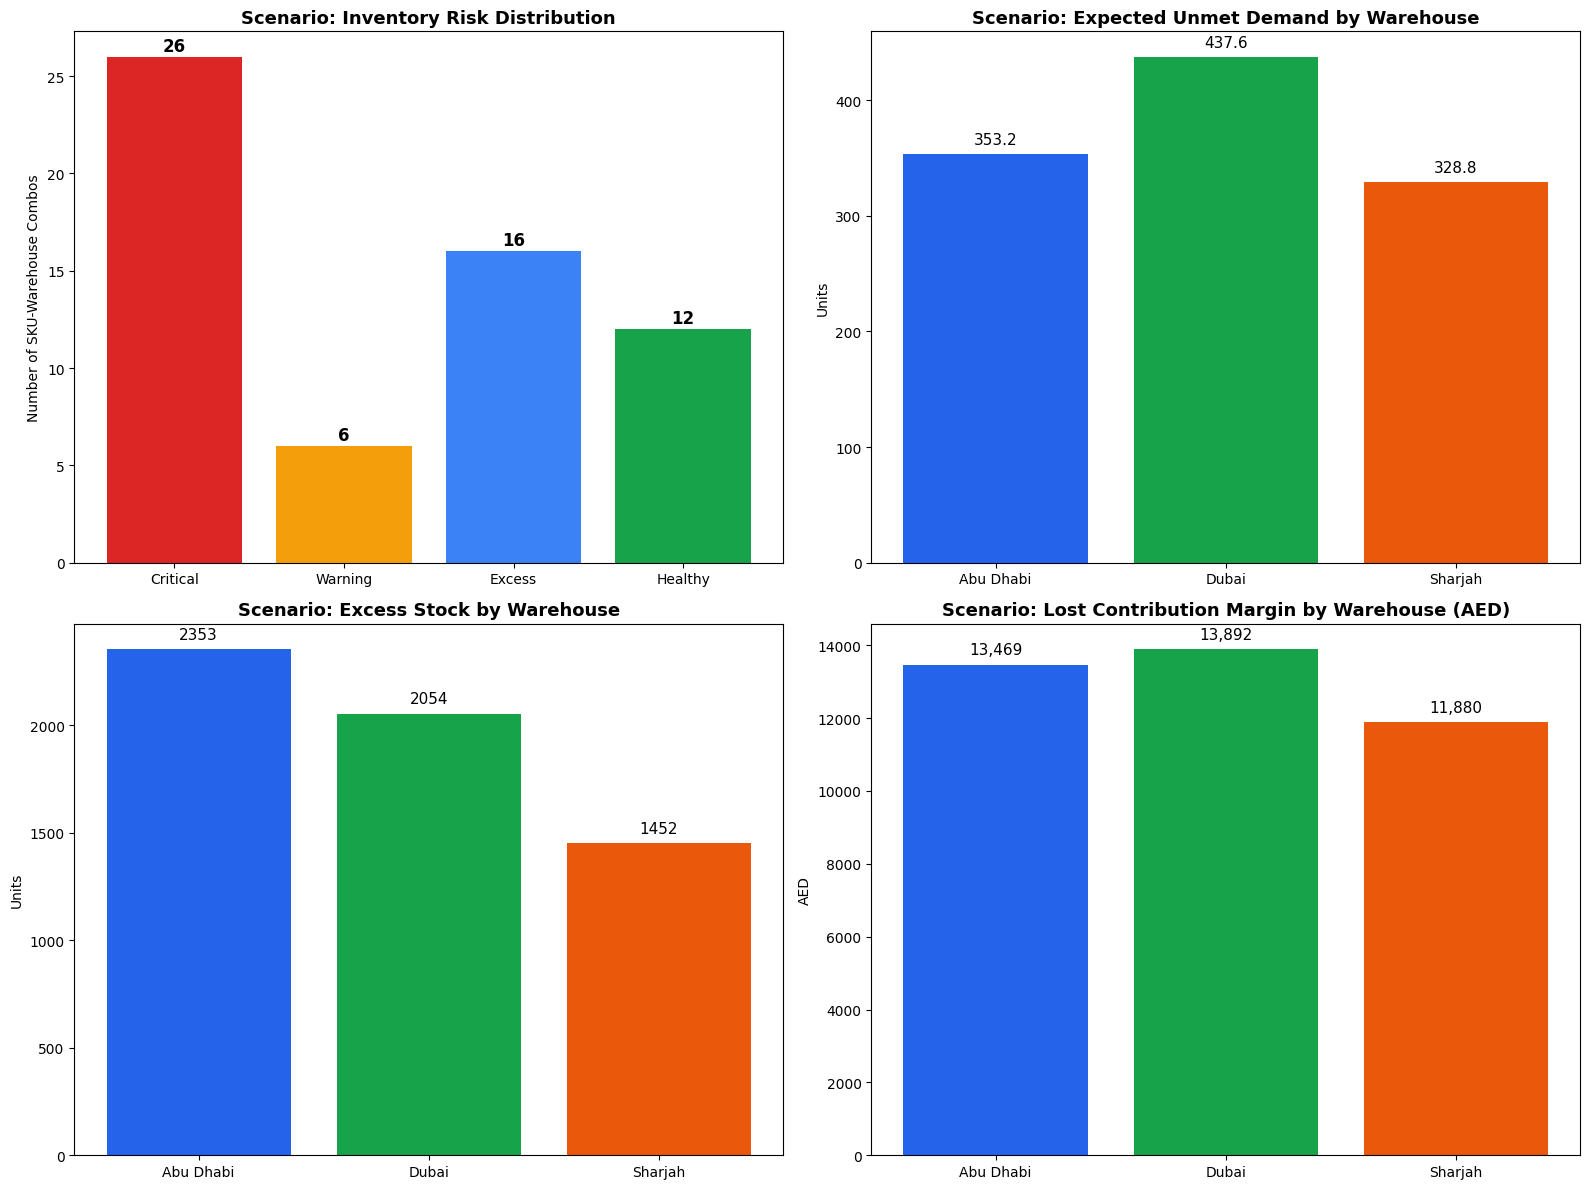

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\scenario_inventory_risk_charts.png


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Risk distribution
ax = axes[0, 0]
risk_order = ["Critical", "Warning", "Excess", "Healthy"]
risk_colors = {"Critical": "#dc2626", "Warning": "#f59e0b", "Excess": "#3b82f6", "Healthy": "#16a34a"}
counts = [risk_counts.get(r, 0) for r in risk_order]
colors = [risk_colors[r] for r in risk_order]
ax.bar(risk_order, counts, color=colors)
ax.set_title("Scenario: Inventory Risk Distribution", fontweight="bold", fontsize=13)
ax.set_ylabel("Number of SKU-Warehouse Combos")
for i, v in enumerate(counts):
    ax.text(i, v + 0.3, str(v), ha="center", fontsize=12, fontweight="bold")

# 2. Shortages by warehouse
ax = axes[0, 1]
wh_short = inv_risk.groupby("Warehouse")["Expected_Unmet_Demand"].sum()
ax.bar(wh_short.index, wh_short.values, color=["#2563eb", "#16a34a", "#ea580c"])
ax.set_title("Scenario: Expected Unmet Demand by Warehouse", fontweight="bold", fontsize=13)
ax.set_ylabel("Units")
for i, (wh, v) in enumerate(wh_short.items()):
    ax.text(i, v + max(wh_short)*0.02 if max(wh_short) > 0 else 0.5, f"{v:.1f}", ha="center", fontsize=11)

# 3. Excess stock by warehouse
ax = axes[1, 0]
wh_excess = inv_risk.groupby("Warehouse")["Excess_Stock"].sum()
ax.bar(wh_excess.index, wh_excess.values, color=["#2563eb", "#16a34a", "#ea580c"])
ax.set_title("Scenario: Excess Stock by Warehouse", fontweight="bold", fontsize=13)
ax.set_ylabel("Units")
for i, (wh, v) in enumerate(wh_excess.items()):
    ax.text(i, v + max(wh_excess)*0.02, f"{v:.0f}", ha="center", fontsize=11)

# 4. Lost margin by warehouse
ax = axes[1, 1]
wh_margin = inv_risk.groupby("Warehouse")["Lost_Contribution_Margin_AED"].sum()
ax.bar(wh_margin.index, wh_margin.values, color=["#2563eb", "#16a34a", "#ea580c"])
ax.set_title("Scenario: Lost Contribution Margin by Warehouse (AED)", fontweight="bold", fontsize=13)
ax.set_ylabel("AED")
for i, (wh, v) in enumerate(wh_margin.items()):
    ax.text(i, v + max(wh_margin)*0.02 if max(wh_margin) > 0 else 5, f"{v:,.0f}", ha="center", fontsize=11)

plt.tight_layout()
plt.savefig(DATA_DIR / "scenario_inventory_risk_charts.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {DATA_DIR / 'scenario_inventory_risk_charts.png'}")

---
## 11. Validation Checks

In [23]:
print("=" * 65)
print("  VALIDATION CHECKS — Step 3.1: Inventory Scenario")
print("=" * 65)

# 1. Exactly 60 SKU-warehouse combinations
assert len(scenario_risks) == 60, f"Expected 60 combos, got {len(scenario_risks)}"
print(f"  ✅ SKU×Warehouse combos       : {len(scenario_risks)} (expected 60)")

# 2. Exactly 1,800 daily inventory projections
assert len(daily_proj_save) == 1800, f"Expected 1800, got {len(daily_proj_save)}"
print(f"  ✅ Daily projections          : {len(daily_proj_save)} (expected 1800)")

# 3. No negative physical inventory
assert (daily_proj_save["Ending_Stock"] < 0).sum() == 0, "Negative ending stock found!"
print(f"  ✅ No negative inventory      : {(daily_proj_save['Ending_Stock'] < 0).sum()} negatives")

# 4. No missing or duplicated records
dups = daily_proj_save.duplicated(subset=["Date", "SKU", "Warehouse"]).sum()
missing = daily_proj_save[["Date", "SKU", "Warehouse", "Ending_Stock"]].isna().any().any()
assert dups == 0, f"Found {dups} duplicates"
assert not missing, "Missing records found"
print(f"  ✅ No duplicates              : {dups}")
print(f"  ✅ No missing records         : {not missing}")

# 5. Incoming shipments applied on correct dates
inbound_check_ok = True
for _, row in sc_inbound.iterrows():
    sku, wh, dt, qty = row["SKU"], row["Warehouse"], row["Expected_Arrival"], row["Quantity"]
    proj_row = daily_proj_save[
        (daily_proj_save["SKU"] == sku) &
        (daily_proj_save["Warehouse"] == wh) &
        (daily_proj_save["Date"] == dt.strftime("%Y-%m-%d"))
    ]
    if len(proj_row) == 0 or proj_row["Incoming_Qty"].values[0] != qty:
        inbound_check_ok = False
        break
assert inbound_check_ok, "Inbound shipments not applied correctly!"
print(f"  ✅ Inbound shipments correct  : all {len(sc_inbound)} orders verified")

# 6. Daily inventory balances reconcile
reconcile_ok = True
for (sku, wh), grp in daily_proj_save.groupby(["SKU", "Warehouse"]):
    grp = grp.sort_values("Date").reset_index(drop=True)
    for i in range(len(grp) - 1):
        ending = grp.loc[i, "Ending_Stock"]
        starting_next = grp.loc[i + 1, "Starting_Stock"]
        if abs(ending - starting_next) > 0.01:
            reconcile_ok = False
            break
    if not reconcile_ok:
        break
assert reconcile_ok, "Daily inventory does not reconcile!"
print(f"  ✅ Daily balances reconcile   : Starting[t+1] == Ending[t]")

# 7. Stock ageing quantities reconcile with Available_Stock
ageing_check = ageing_wide.copy()
ageing_check = ageing_check.merge(scenario_inventory[["SKU", "Warehouse", "Available_Stock"]],
                                   on=["SKU", "Warehouse"])
ageing_mismatches = (ageing_check["Total_Aged_Stock"] != ageing_check["Available_Stock"]).sum()
assert ageing_mismatches == 0, f"{ageing_mismatches} ageing mismatches!"
print(f"  ✅ Ageing reconciles          : {ageing_mismatches} mismatches out of {len(ageing_check)}")

# 8. All nonnegative integer stock quantities
assert (scenario_inventory["Available_Stock"] >= 0).all()
assert (scenario_inventory["Reserved_Stock"] >= 0).all()
assert (scenario_inventory["Safety_Stock"] >= 0).all()
assert scenario_inventory["Available_Stock"].dtype.kind in "iu"
assert scenario_inventory["Reserved_Stock"].dtype.kind in "iu"
assert scenario_inventory["Safety_Stock"].dtype.kind in "iu"
print(f"  ✅ Nonnegative integers       : all stock quantities verified")

# 9. Both shortages and excess inventory exist
n_critical = risk_counts.get("Critical", 0)
n_warning = risk_counts.get("Warning", 0)
n_excess = risk_counts.get("Excess", 0)
assert n_critical > 0 or n_warning > 0, "No shortage cases!"
assert n_excess > 0, "No excess cases!"
print(f"  ✅ Shortages exist            : {n_critical} Critical + {n_warning} Warning")
print(f"  ✅ Excess inventory exists     : {n_excess} cases")

# 10. Transfer opportunities exist
assert n_transfer_skus > 0, "No transfer opportunities!"
print(f"  ✅ Transfer opportunities     : {n_transfer_skus} SKUs, {len(transfer_df)} pairs")

# 11. All forecasts from improved XGBoost
assert (scenario_risks["Selected_Model"] == "Tuned XGBoost").all()
print(f"  ✅ All forecasts from XGBoost : {(scenario_risks['Selected_Model'] == 'Tuned XGBoost').sum()}/60")

# 12. Original files not overwritten
orig_inv = pd.read_csv(DATA_DIR / "inventory.csv")
assert len(orig_inv) == 60, "Original inventory modified!"
print(f"  ✅ Original files preserved  : inventory.csv unchanged")

print("=" * 65)
print("  ALL VALIDATION CHECKS PASSED ✅")
print("=" * 65)

  VALIDATION CHECKS — Step 3.1: Inventory Scenario
  ✅ SKU×Warehouse combos       : 60 (expected 60)
  ✅ Daily projections          : 1800 (expected 1800)
  ✅ No negative inventory      : 0 negatives
  ✅ No duplicates              : 0
  ✅ No missing records         : True
  ✅ Inbound shipments correct  : all 15 orders verified
  ✅ Daily balances reconcile   : Starting[t+1] == Ending[t]
  ✅ Ageing reconciles          : 0 mismatches out of 60
  ✅ Nonnegative integers       : all stock quantities verified
  ✅ Shortages exist            : 26 Critical + 6 Warning
  ✅ Excess inventory exists     : 16 cases
  ✅ Transfer opportunities     : 14 SKUs, 23 pairs
  ✅ All forecasts from XGBoost : 60/60
  ✅ Original files preserved  : inventory.csv unchanged
  ALL VALIDATION CHECKS PASSED ✅


---
## 12. Final Report

In [24]:
print("=" * 65)
print("  STEP 3.1 REPORT — Inventory Scenario Results")
print("=" * 65)
print()
print(f"  1. Critical cases             : {n_critical}")
print(f"  2. Warning cases              : {n_warning}")
print(f"  3. Excess cases                : {n_excess}")
print(f"  4. Healthy cases              : {risk_counts.get('Healthy', 0)}")
print(f"  5. Total expected unmet demand: {inv_risk['Expected_Unmet_Demand'].sum():.1f} units")
print(f"  6. Total excess inventory      : {inv_risk['Excess_Stock'].sum():.1f} units")
print(f"  7. SKUs with transfer opportun: {n_transfer_skus}")
print(f"     Total transfer pairs        : {len(transfer_df)}")
print(f"     Fully coverable             : {transfer_df['Can_Fully_Cover'].sum() if len(transfer_df) > 0 else 0}")
print()
print("  Files Created:")
print(f"    scenario_inventory.csv            ({len(scenario_inventory)} rows)")
print(f"    scenario_stock_ageing.csv         ({len(scenario_stock_ageing)} rows)")
print(f"    scenario_inbound_orders.csv       ({len(scenario_inbound)} rows)")
print(f"    scenario_inventory_risks.csv      ({len(scenario_risks)} rows)")
print(f"    scenario_daily_inventory_projection.csv ({len(daily_proj_save)} rows)")
print(f"    scenario_inventory_risk_summary.csv ({len(risk_summary)} rows)")
print(f"    scenario_inventory_risk_charts.png")
print()
print("  Random seed: 42")
print("  All original files preserved.")
print("  Step 4 not implemented yet.")
print("=" * 65)

  STEP 3.1 REPORT — Inventory Scenario Results

  1. Critical cases             : 26
  2. Warning cases              : 6
  3. Excess cases                : 16
  4. Healthy cases              : 12
  5. Total expected unmet demand: 1119.7 units
  6. Total excess inventory      : 5858.6 units
  7. SKUs with transfer opportun: 14
     Total transfer pairs        : 23
     Fully coverable             : 23

  Files Created:
    scenario_inventory.csv            (60 rows)
    scenario_stock_ageing.csv         (240 rows)
    scenario_inbound_orders.csv       (15 rows)
    scenario_inventory_risks.csv      (60 rows)
    scenario_daily_inventory_projection.csv (1800 rows)
    scenario_inventory_risk_summary.csv (28 rows)
    scenario_inventory_risk_charts.png

  Random seed: 42
  All original files preserved.
  Step 4 not implemented yet.
